# Building a continuous futures price series: raw splice vs adjusted

**ICE Cotton No. 2, daily, 2010–2026**

A futures "price history" isn't one price. It's a chain of separate contracts. ICE cotton trades Mar, May, Jul, Oct and Dec contracts. Each starts thin, becomes the most traded, then empties out before delivery and expires. To model price over many years, you need to join them into one series. Done carelessly, the joins create moves that never happened, and every model built on top inherits them.

This notebook builds the series step by step on real data and measures what goes wrong with a simple splice:

| # | Problem | Cotton example | What goes wrong in a model | Fix |
|---|---|---|---|---|
| 1 | **Roll gaps** | Switching from Jul to Dec: the two contracts trade at different prices | The switch shows up as a big one-day "move" nobody earned or lost | Measure each day's return **within one contract**, then chain the returns. Never subtract prices across a roll |
| 2 | **Old crop → new crop break** | Jul (last contract of one crop) → Dec (next crop) | Price jumps to a different supply/demand balance; the model treats it as one thing continuing | Mark these rolls. For crop-specific studies, price the contract that delivers the crop being studied, or build a separate new-crop (Dec-only) series |
| 3 | **Notice period / expiry** | Positions are closed out, open interest drains, delivery squeezes can happen | Odd, distorted moves in a contract's last weeks | Roll **before** first notice day, at the point where traders actually switch |
| 4 | **Thin contracts** | Far-dated contracts, and the Oct contract | Settlements set with few or no trades → fake "0% days" → the series looks calmer and more predictable than it is | Hold only the liquid contract; flag low-volume days |
| 5 | **Daily price limits** | ICE caps each day's move (3–7 cents) | A limit-locked day hides the true move, which spills into the next day → fake momentum | Flag limit days; check results with and without them |
| 6 | **Calendar gaps** | Weekends, holidays; scheduled report days | A Monday return covers 3 days; report days are more volatile by design | Mark gaps; treat scheduled report days as known volatility events |
| 7 | **Price levels drift** | Inflation; the 2010–11 and 2021–22 spikes | Levels trend and change regime, so models on levels mislead | Model **log returns**, not price levels |

**What you'll end up with:** three versions of the same history (raw splice, ratio-adjusted, difference-adjusted), a clean daily return series with flags for every problem day, and the evidence for each rule.

> **Data.** The prices come from Barchart and aren't included, because the licence doesn't allow redistribution. All outputs below come from the author's run. To reproduce, put one CSV per contract in `data/` (format in `data/README.md`) or set `FUTURES_DATA_DIR`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import continuous_futures as cf

DATA_DIR = os.environ.get("FUTURES_DATA_DIR", "data")
BLUE, ORANGE, RED, GREY = "#3b6ea5", "#e69f00", "#c0504d", "#9a9a9a"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.width", 160)

cal, contracts = cf.load_contracts(DATA_DIR)
print(f"{len(contracts)} contracts, {len(cal):,} trading days, {cal[0].date()} to {cal[-1].date()}")
print("cycle used:", cf.COTTON_CYCLE, "(Mar, May, Jul, Dec; Oct is skipped as thin)")

70 contracts, 4,759 trading days, 2007-11-19 to 2026-10-16
cycle used: ['H', 'K', 'N', 'Z'] (Mar, May, Jul, Dec; Oct is skipped as thin)


## 1. When to switch contracts

**First notice day (FND).** From this day, holders of a long position can be handed physical cotton. For ICE cotton it's **five business days before the first business day of the delivery month**. Speculators and most hedgers leave before it, so liquidity drains and prices can be distorted by delivery positioning (problem 3).

**When do traders actually switch?** For every pair (expiring contract, next contract), count the trading days before FND at which the next contract's volume first exceeds the expiring one's, and the same for open interest. The roll rule should follow this, not a guess.

In [2]:
cross = cf.volume_crossover(contracts, cal)
summary = cross.groupby(cross.contract.str[-3]).agg(
    pairs=("contract", "size"),
    volume_switch_median=("volume_cross", "median"), volume_switch_max=("volume_cross", "max"),
    oi_switch_median=("oi_cross", "median"))
summary.index = summary.index.map({"H": "Mar→May", "K": "May→Jul", "N": "Jul→Dec", "Z": "Dec→Mar"})
summary

,pairs,volume_switch_median,volume_switch_max,oi_switch_median
contract,,,,
Mar→May,16,6.0,8,9.0
May→Jul,17,7.0,10,11.0
Jul→Dec,17,10.0,18,18.0
Dec→Mar,16,7.0,10,11.5


**Reading the table:** trading days before first notice when the crowd moves. Volume switches **6–7 days** before FND for Mar, May and Dec, and about **10 days** for Jul→Dec, where traders move into the new crop earlier.

**Rule used: roll at the close 10 trading days before first notice, for every contract.** It's fixed before looking at any returns (so it can't be tuned to flatter results), it's at or ahead of the crowd for most rolls, and it stays well clear of the notice period.

The chart below shows one real roll: the expiring Jul 2024 contract emptying out while Dec 2024 takes over.

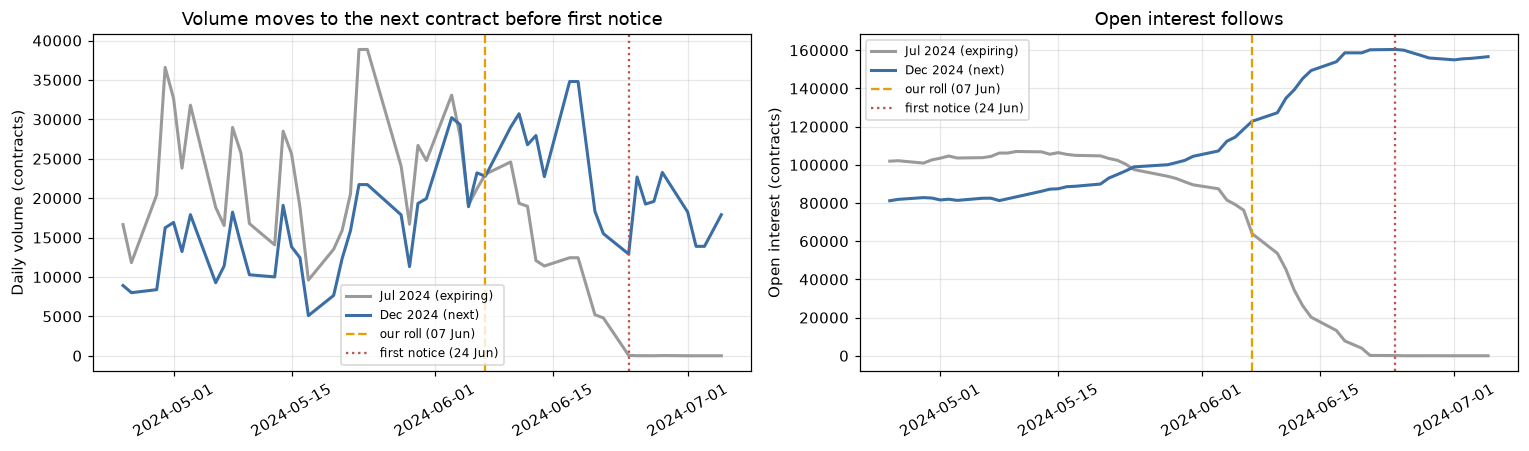

In [3]:
old, new = contracts["CTN24"], contracts["CTZ24"]
ext = cf.extend_calendar(cal)
fnd, roll = cf.first_notice_day("CTN24", ext), cf.roll_date("CTN24", ext, 10)
w = slice(fnd - pd.Timedelta(days=60), fnd + pd.Timedelta(days=12))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, col, lab in [(axes[0], "volume", "Daily volume (contracts)"), (axes[1], "oi", "Open interest (contracts)")]:
    ax.plot(old.loc[w, col], color=GREY, lw=2, label="Jul 2024 (expiring)")
    ax.plot(new.loc[w, col], color=BLUE, lw=2, label="Dec 2024 (next)")
    ax.axvline(roll, color=ORANGE, ls="--", lw=1.5, label=f"our roll ({roll:%d %b})")
    ax.axvline(fnd, color=RED, ls=":", lw=1.5, label=f"first notice ({fnd:%d %b})")
    ax.set_ylabel(lab); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=30)
axes[0].set_title("Volume moves to the next contract before first notice")
axes[1].set_title("Open interest follows")
fig.tight_layout(); plt.show()

**How to read it:** grey = the expiring contract, blue = the next one. Orange dashed = where this series rolls; red dotted = first notice day. Volume crosses over around our roll date; by first notice, the expiring contract is a shadow of itself.

## 2. Build the chain, three ways

`build_chain` holds one contract at a time and rolls 10 trading days before each first notice. For every day it keeps the **real settlement** of the contract held, and two returns:

* `ret` = ln(today's settle ÷ yesterday's settle) **of the same contract**: the clean return.
* `naive_ret` = ln(today's settle ÷ the previous row's settle), which on the day after a roll compares two different contracts. This is what a careless splice produces.

Three price series can then be built:

| Series | How | Daily % moves | Price level | Use for |
|---|---|---|---|---|
| **Raw splice** | Real settlements of whichever contract was held | Wrong on roll days | Real on every day | Seeing what actually traded |
| **Ratio-adjusted** | Chain the clean returns, scale so the last value = today's price | **Exact** | Not real before the last roll | Returns, volatility, % models, charts |
| **Difference-adjusted ("Panama")** | Shift earlier prices by the **cents** gap at each later roll | Distorted | Not real; can even turn negative | Cent P&L of a rolled position |

In [4]:
a = cf.build_chain(contracts, cal, first="CTK10", first_prev="CTH10", days_before_fnd=10)
a["ratio_adj"] = cf.ratio_adjusted(a)
a["panama_adj"] = cf.difference_adjusted(a)
flags = cf.flag_days(a)
print(f"{len(a):,} trading days, {a.index[0].date()} to {a.index[-1].date()}, "
      f"{a.contract.nunique()} contracts, {int(a.roll_day.sum())} rolls, now holding {a.contract.iloc[-1]}")

# sanity checks: every return is within one contract, both adjusted series end at today's real price
assert np.allclose(np.log(a.ratio_adj).diff().iloc[1:], a.ret.iloc[1:])
assert np.allclose(a.panama_adj.diff().iloc[1:], (a.settle - a.prev_settle).iloc[1:])
assert np.isclose(a.ratio_adj.iloc[-1], a.settle.iloc[-1]) and np.isclose(a.panama_adj.iloc[-1], a.settle.iloc[-1])
print("checks passed: no jumps at rolls in either adjusted series; both end at today's settle")

4,203 trading days, 2010-02-08 to 2026-10-16, 67 contracts, 66 rolls, now holding CTZ26
checks passed: no jumps at rolls in either adjusted series; both end at today's settle


**One real roll, step by step: 9 June 2022, Jul 22 → Dec 22.** That day Jul settled at 146.51c and Dec at 124.93c, because old-crop cotton was very tight (problem 2).

In [5]:
example = a.loc["2022-06-07":"2022-06-13",
                ["contract", "settle", "next_contract", "next_settle", "ret", "naive_ret", "ratio_adj", "panama_adj"]]
example.assign(ret=example.ret * 100, naive_ret=example.naive_ret * 100).round(2)

,contract,settle,next_contract,next_settle,ret,naive_ret,ratio_adj,panama_adj
date,,,,,,,,
2022-06-07,CTN22,136.95,NaN,NaN,-0.58,-0.58,149.50,132.64
2022-06-08,CTN22,140.62,NaN,NaN,2.64,2.64,153.50,136.31
2022-06-09,CTN22,146.51,CTZ22,124.93,4.10,4.10,159.93,142.20
2022-06-10,CTZ22,122.36,NaN,NaN,-2.08,-18.01,156.64,139.63
2022-06-13,CTZ22,122.81,NaN,NaN,0.37,0.37,157.22,140.08


**Reading the table:** on 10 June the careless splice (`naive_ret`) compares Dec's 122.36c with Jul's 146.51c the day before, and books log returns **−18%** ln(122.63/146.51). The clean return compares Dec with Dec (124.93 → 122.36): log returns**−2.1%**. Both adjusted series move smoothly through the roll.


lowest value: raw 48.4c, ratio-adjusted 52.7c, Panama 20.5c


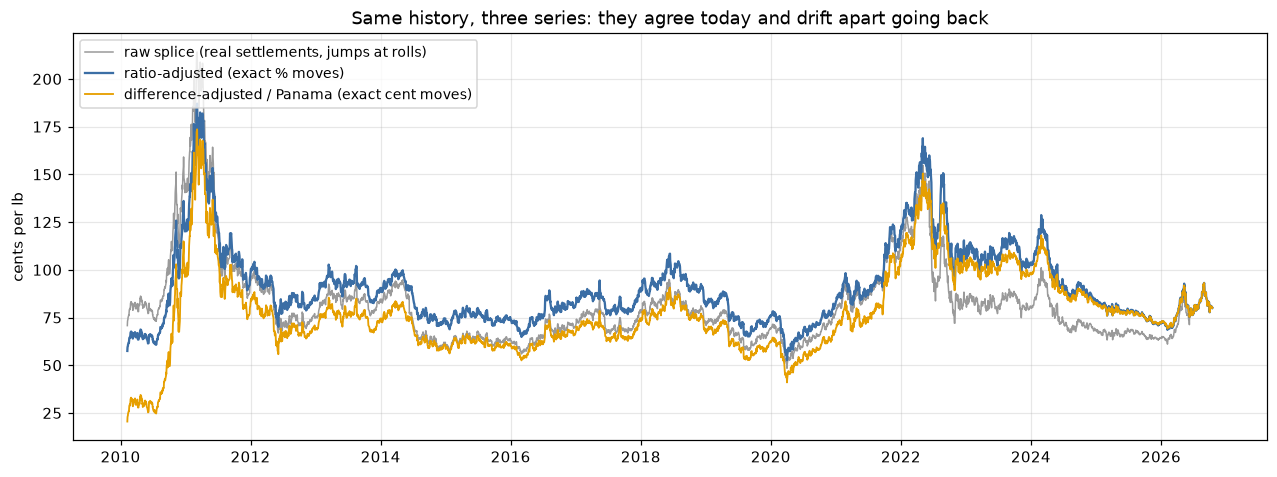

In [6]:
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(a.settle, color=GREY, lw=1, label="raw splice (real settlements, jumps at rolls)")
ax.plot(a.ratio_adj, color=BLUE, lw=1.5, label="ratio-adjusted (exact % moves)")
ax.plot(a.panama_adj, color=ORANGE, lw=1.2, label="difference-adjusted / Panama (exact cent moves)")
ax.set_ylabel("cents per lb"); ax.legend(fontsize=9, loc="upper left")
ax.set_title("Same history, three series: they agree today and drift apart going back")
plt.show()
print(f"lowest value: raw {a.settle.min():.1f}c, ratio-adjusted {a.ratio_adj.min():.1f}c, Panama {a.panama_adj.min():.1f}c")

**How to read it:** the three lines meet at the right-hand end (today's real price) and drift apart going back, because each roll gap adds up. Cotton's real low in this period was 48.4c. The Panama series goes down to about 20c: cent gaps subtracted from a price level distort it badly over 16 years. **For returns and % models use ratio adjustment; for actual price levels use the raw settlements.**

## 3. Problems 1 and 2: roll gaps, and the old-crop → new-crop break

The **roll gap** is how far the new contract was from the old one on the roll day, i.e. the fake move a careless splice would book the next day.

In [7]:
rolls = a[a.roll_day].copy()
rolls["gap_pct"] = rolls.roll_gap * 100
names = {"H->K": "Mar→May", "K->N": "May→Jul", "N->Z": "Jul→Dec (old→new crop)", "Z->H": "Dec→Mar"}
typical = a.ret.abs().mean() * 100
by_type = rolls.groupby(rolls.roll_type.map(names)).gap_pct.agg(["count", "mean", "min", "max"]).round(2)
print(f"typical daily move: {typical:.2f}%   rolls with a gap bigger than that: "
      f"{(rolls.gap_pct.abs() > typical).sum()} of {len(rolls)}")
by_type

typical daily move: 1.15%   rolls with a gap bigger than that: 42 of 66


,count,mean,min,max
roll_type,,,,
Dec→Mar,16,0.68,-3.57,3.46
Jul→Dec (old→new crop),17,-3.04,-15.93,5.51
Mar→May,16,0.85,-2.14,3.19
May→Jul,17,0.39,-6.66,2.84


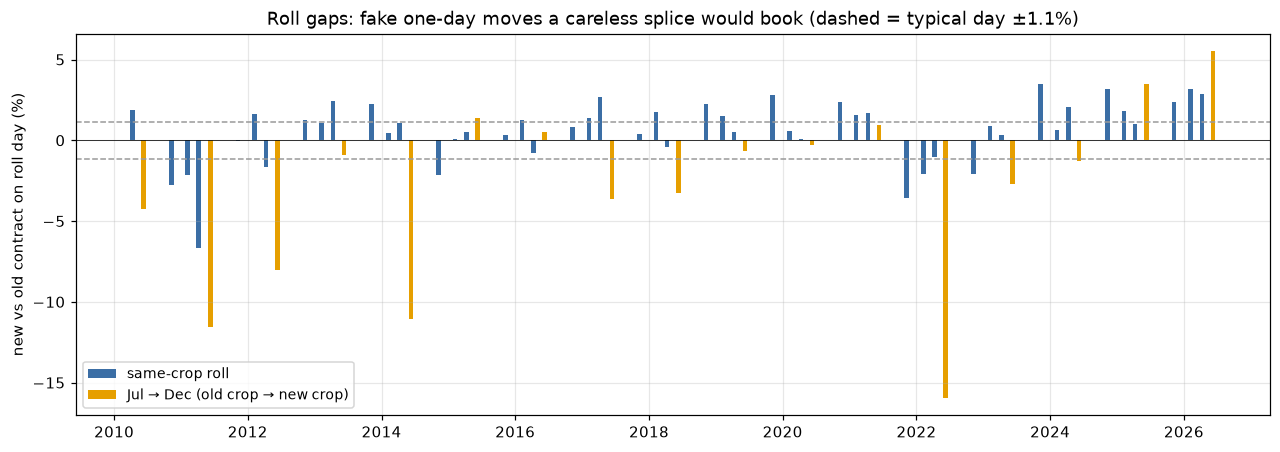

In [8]:
fig, ax = plt.subplots(figsize=(14, 4.5))
crop = rolls.roll_type == "N->Z"
ax.bar(rolls.index[~crop], rolls.gap_pct[~crop], width=25, color=BLUE, label="same-crop roll")
ax.bar(rolls.index[crop], rolls.gap_pct[crop], width=25, color=ORANGE, label="Jul → Dec (old crop → new crop)")
for v in (typical, -typical):
    ax.axhline(v, color=GREY, ls="--", lw=1)
ax.axhline(0, color="k", lw=.5)
ax.set_ylabel("new vs old contract on roll day (%)")
ax.set_title(f"Roll gaps: fake one-day moves a careless splice would book (dashed = typical day ±{typical:.1f}%)")
ax.legend(fontsize=9, loc="lower left"); plt.show()

**How to read it:** one bar per roll. Bars beyond the dashed lines are fake moves bigger than a normal trading day. **Orange (Jul → Dec) bars are the largest**: the new crop is a different balance sheet, so when the old crop is tight it trades far above the new crop (2011, 2012, 2014, 2022). Same-crop rolls (blue) are smaller and usually slightly positive, reflecting storage costs.

**What it does to the statistics.** The same days, measured three ways: the clean chain, the careless splice, and a widely used free "continuous" series that rolls late (Yahoo `CT=F`, if available locally):

In [9]:
cmp = {"clean chain (ret)": cf.describe_returns(a.ret), "careless splice (naive_ret)": cf.describe_returns(a.naive_ret)}
yahoo_file = os.environ.get("YAHOO_CT_FILE", os.path.join(DATA_DIR, "ct_continuous.csv"))
if os.path.exists(yahoo_file):
    y = pd.read_csv(yahoo_file, header=[0, 1], index_col=0, parse_dates=True)[("Close", "CT=F")].dropna()
    y_ret = np.log(y / y.shift(1)).reindex(a.index)
    cmp["Yahoo CT=F (same days)"] = cf.describe_returns(y_ret)
    off = ((y_ret - a.ret).abs() > .015).sum()
    print(f"days where Yahoo's move differs from the clean chain by more than 1.5%: {off}")
pd.DataFrame(cmp).round(2)

days where Yahoo's move differs from the clean chain by more than 1.5%: 189


,clean chain (ret),careless splice (naive_ret),Yahoo CT=F (same days)
days,4203.00,4202.00,4196.00
std %,1.57,1.64,1.77
excess kurtosis,1.22,5.87,16.67
lag-1 autocorr,0.07,0.05,0.11
biggest day %,7.12,18.01,27.29
days beyond ±3%,336.00,356.00,381.00


**Reading the table:** a careless splice multiplies the fat-tail measure (excess kurtosis) several times over, and turns the biggest day from about 7% into about 18%. A volatility model fitted on it would think cotton is far more crash-prone than it is. The free continuous series is worse still, because it rolls inside the notice period.

## 4. Problems 3 and 4: the notice period and thin contracts

Holding a contract into its notice period, or a contract more than a year from expiry, means pricing from a market where almost nobody trades. The chart shows median daily volume of a contract by how many trading days remain before its first notice day, across all contracts.

days in our chain with zero volume or no price range: 2; with fewer than 1,000 contracts traded: 3


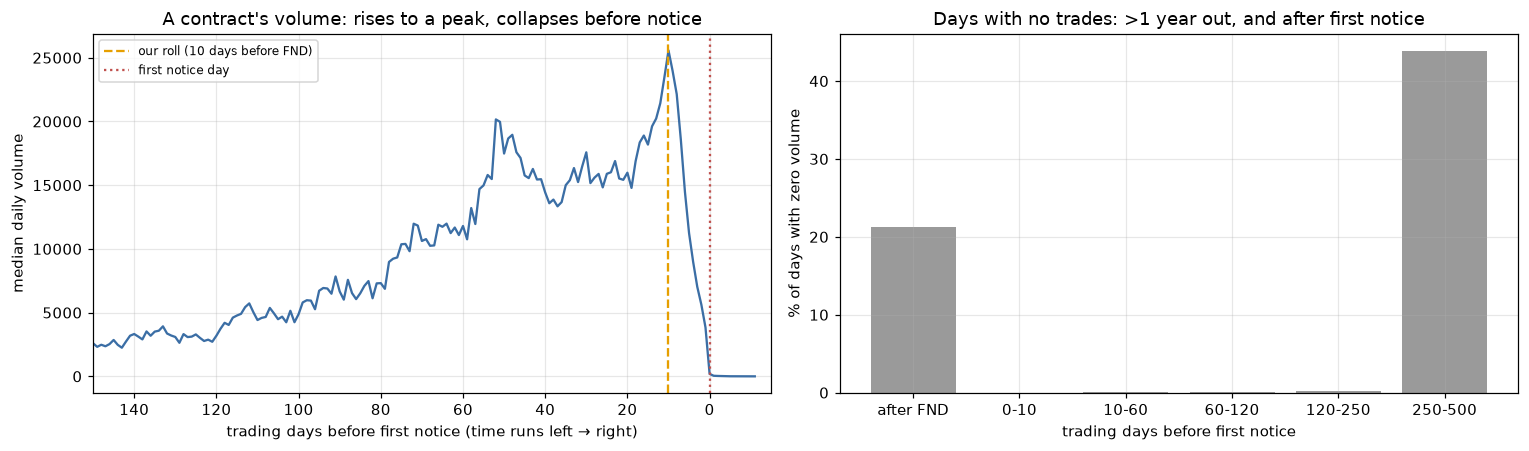

In [10]:
rows = []
for sym, s in contracts.items():
    if sym[-3] not in cf.COTTON_CYCLE or s.settle.last_valid_index() is None:
        continue
    f = cf.first_notice_day(sym, ext)
    live = s.dropna(subset=["settle"])
    k = pd.Series([ext.get_loc(f) - ext.get_loc(t) for t in live.index], index=live.index)
    rows.append(pd.DataFrame({"days_to_fnd": k, "volume": live.volume}))
v = pd.concat(rows)
v = v[(v.days_to_fnd >= -15) & (v.days_to_fnd <= 500)]
med = v.groupby("days_to_fnd").volume.median()
zero = v.assign(z=v.volume == 0).groupby(pd.cut(v.days_to_fnd, [-16, 0, 10, 60, 120, 250, 500])).z.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(med.index, med.values, color=BLUE, lw=1.5)
axes[0].axvline(10, color=ORANGE, ls="--", label="our roll (10 days before FND)")
axes[0].axvline(0, color=RED, ls=":", label="first notice day")
axes[0].set_xlim(150, -15); axes[0].set_xlabel("trading days before first notice (time runs left → right)")
axes[0].set_ylabel("median daily volume"); axes[0].legend(fontsize=8)
axes[0].set_title("A contract's volume: rises to a peak, collapses before notice")
axes[1].bar(range(len(zero)), zero.values, color=GREY)
axes[1].set_xticks(range(len(zero)))
axes[1].set_xticklabels(["after FND", "0-10", "10-60", "60-120", "120-250", "250-500"])
axes[1].set_xlabel("trading days before first notice"); axes[1].set_ylabel("% of days with zero volume")
axes[1].set_title("Days with no trades: >1 year out, and after first notice")
fig.tight_layout(); plt.show()
print(f"days in our chain with zero volume or no price range: {int(flags.stale.sum())}; "
      f"with fewer than 1,000 contracts traded: {int(flags.thin.sum())}")

**How to read it:**
* **Left:** volume of a typical contract as it approaches first notice; time runs left to right. It peaks while the contract is the front month, then collapses. Our roll (orange) sits before the collapse.
* **Right:** share of days with no trades at all, by distance from first notice. More than about a year before expiry (250–500 trading days), **over 40% of days have no trades**, and after first notice about **1 day in 5**. Those settlements are set by the exchange, not by trading, so a series built from them would show fake "0% days". In between, a contract trades every day.

The clean chain holds only the liquid contract: just a handful of stale or thin days in 16 years.

## 5. Problem 5: daily price limits create fake momentum

ICE limits how far cotton can move in a day (3–7 cents depending on price level). When the limit is hit and the market locks, the rest of the move has to wait for the next session. A limit day is flagged when the settle moved by exactly a limit amount **and** closed at the day's high or low.

In [11]:
nxt = a.ret.shift(-1)
same_c = a.contract.shift(-1) == a.contract
rows = {}
for lab, m in [("closed at the limit", flags.limit),
               ("big move (>2.5%), not at limit", (a.ret.abs() > .025) & ~flags.limit),
               ("all days", a.ret.notna())]:
    x = (np.sign(a.ret) * nxt)[m & same_c].dropna() * 100
    rows[lab] = {"days": len(x), "next day same direction %": (x > 0).mean() * 100,
                 "avg follow-through %": x.mean()}
L = a[flags.limit & same_c]
gap_open = np.sign(L.ret) * np.log(a.open.shift(-1)[L.index] / L.settle) * 100
excl = ~(flags.limit | flags.after_limit)
print("limit days by year:", flags.limit.groupby(a.index.year).sum().loc[lambda s: s > 0].to_dict())
print(f"after a limit close, the next OPEN gaps the same way {(gap_open > 0).mean():.0%} of the time "
      f"(avg {gap_open.mean():+.2f}%)")
print(f"lag-1 autocorrelation of daily returns: all days {a.ret.autocorr(1):+.3f}; "
      f"without limit days and the day after {a.ret.where(excl).autocorr(1):+.3f}")
pd.DataFrame(rows).T.round(2)

limit days by year: {2010: 32, 2011: 49, 2012: 8, 2013: 2, 2016: 2, 2017: 5, 2018: 3, 2019: 2, 2021: 5, 2022: 28, 2023: 4, 2024: 8, 2025: 1, 2026: 2}
after a limit close, the next OPEN gaps the same way 83% of the time (avg +0.79%)
lag-1 autocorrelation of daily returns: all days +0.070; without limit days and the day after -0.007


,days,next day same direction %,avg follow-through %
closed at the limit,150.0,69.33,1.18
"big move (>2.5%), not at limit",344.0,47.38,0.02
all days,4136.0,49.15,0.05


**Reading the output:** after a limit close, the next day continues in the same direction about **7 times in 10**. A big move that *didn't* hit the limit carries on only half the time, which is chance. Most of the carry-over happens in the **opening gap**, which you can't trade at the limit settle.

**This is the series' only day-to-day memory.** Remove limit days and lag-1 autocorrelation drops to about zero. An ARIMA model fitted without flagging them will "discover" momentum that's really just the exchange's limit rule.

## 6. Problem 6: calendar gaps and scheduled report days

Returns after weekends and holidays cover more than one day of news. Scheduled reports, such as USDA's monthly WASDE, concentrate news on known days. Both are known in advance and should be flags, not surprises. WASDE release dates are public (USDA) and included in `wasde_release_dates.csv`.

In [12]:
wasde = pd.to_datetime(pd.read_csv("wasde_release_dates.csv").release_date)
flags["wasde"] = a.index.isin(wasde)
r = a.ret.abs() * 100
day_type = np.select([flags.wasde, flags.holiday_gap, a.index.dayofweek == 0],
                     ["WASDE report day", "first day after a holiday", "Monday (after weekend)"], "other days")
pd.DataFrame({"days": r.groupby(day_type).size(),
              "average absolute move %": r.groupby(day_type).mean()}).round(2)

,days,average absolute move %
Monday (after weekend),745,1.19
WASDE report day,196,1.31
first day after a holiday,152,1.19
other days,3110,1.13


**Reading the table:** WASDE report days move about **16% more** than ordinary days (1.31% vs 1.13%). Mondays and post-holiday days, which cover extra calendar time, move only about 5% more. Keep all of these as flags. In a volatility model they're known-in-advance effects, not shocks.

## 7. Problem 7: model returns, not price levels

Most time-series models (ARIMA, regressions on price) assume the series is **stationary**: same average, spread and memory in every period. Two standard tests come at this from opposite sides:

* **ADF** assumes the series *wanders* (not stationary) and tries to reject that. A stat below the critical value = stationary.
* **KPSS** assumes it *is* stationary and tries to reject that. A stat above the critical value = not stationary.

In [13]:
lp, rt = np.log(a.ratio_adj), a.ret.dropna()
rows = {}
for lab, y in [("log price (ratio-adjusted)", lp), ("daily log return", rt)]:
    t_adf, cv_a = cf.adf(y)
    s_kpss, cv_k = cf.kpss(y)
    adf_says = ("stationary" if t_adf < cv_a["1%"] else
                "borderline (stationary at 5%, not at 1%)" if t_adf < cv_a["5%"] else "wanders")
    rows[lab] = {"ADF stat": round(t_adf, 2), "ADF crit 5% / 1%": f"{cv_a['5%']:.2f} / {cv_a['1%']:.2f}",
                 "ADF says": adf_says, "KPSS stat": round(s_kpss, 3), "KPSS crit 5%": cv_k["5%"],
                 "KPSS says": "stationary" if s_kpss < cv_k["5%"] else "not stationary"}
pd.DataFrame(rows).T

,ADF stat,ADF crit 5% / 1%,ADF says,KPSS stat,KPSS crit 5%,KPSS says
log price (ratio-adjusted),-2.99,-2.86 / -3.43,"borderline (stationary at 5%, not at 1%)",0.636,0.463,not stationary
daily log return,-60.44,-2.86 / -3.43,stationary,0.111,0.463,stationary


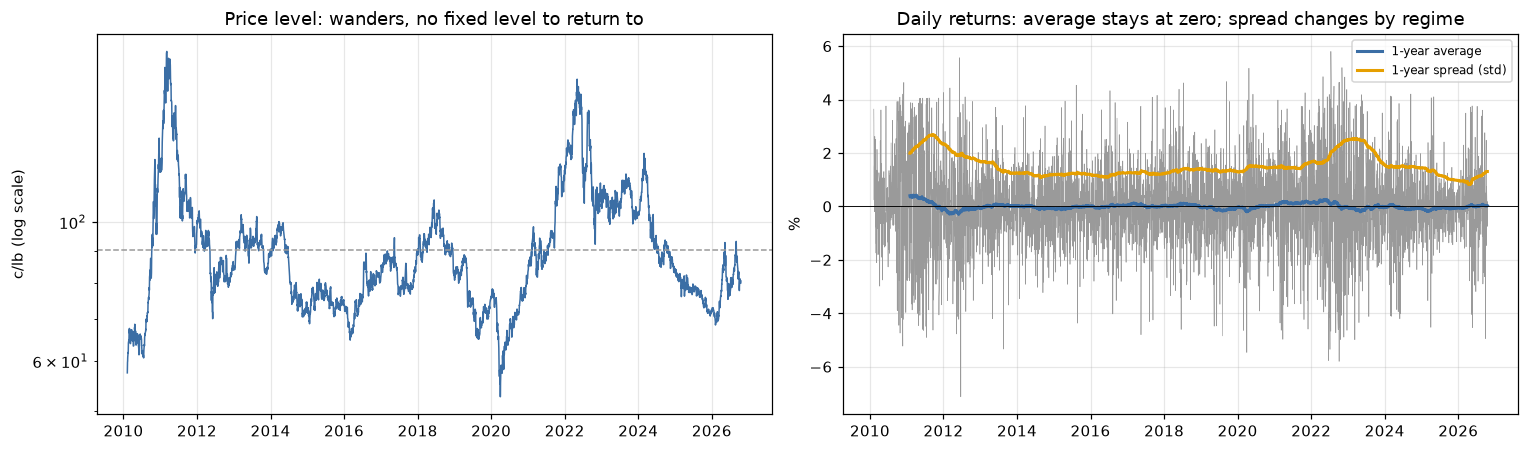

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(a.ratio_adj, color=BLUE, lw=1); axes[0].set_yscale("log")
axes[0].axhline(a.ratio_adj.mean(), color=GREY, ls="--", lw=1)
axes[0].set_title("Price level: wanders, no fixed level to return to"); axes[0].set_ylabel("c/lb (log scale)")
axes[1].plot(rt * 100, color=GREY, lw=.4)
axes[1].plot(rt.rolling(250).mean() * 100, color=BLUE, lw=2, label="1-year average")
axes[1].plot(rt.rolling(250).std() * 100, color=ORANGE, lw=2, label="1-year spread (std)")
axes[1].axhline(0, color="k", lw=.6)
axes[1].set_title("Daily returns: average stays at zero; spread changes by regime"); axes[1].set_ylabel("%")
axes[1].legend(fontsize=8); fig.tight_layout(); plt.show()

**How to read it:**
* **Left:** the price level drifts for years at a time, from about 50c to over 150c, with no level it keeps returning to.
* **Right:** daily returns (grey) stay centred on zero (blue), so the average is stable. Their spread (orange) changes by regime: calm years versus 2011 and 2022.

**Takeaways:**
1. **Model returns** (ARIMA's d = 1).
2. ADF calls the level borderline on the full 16 years (−2.99 vs −2.86 at 5%) only because of the two spike-and-return episodes. In any sub-period it wanders, and KPSS rejects stationarity.
3. The changing spread is what volatility models (GARCH) are for.

## 8. Checklist

| Step | Rule | Evidence in this notebook |
|---|---|---|
| Returns | Always within one contract; never subtract prices across a roll | June 2022: −18% fake vs −2.1% real |
| Roll timing | Close N trading days before first notice, N from where volume actually switches (10 for cotton) | Section 1 |
| Old → new crop | Mark these rolls; use a crop-matched or Dec-only series for crop questions | Jul→Dec gaps up to −16% |
| Adjusted price | Ratio adjustment for % work; raw settlements for real price levels; avoid Panama for long % histories | Panama falls to ~20c vs a real low of 48.4c |
| Liquidity | Hold only the liquid contract; flag thin and stale days | Section 4 |
| Limits | Flag limit days and the day after; test models with and without | The only lag-1 memory in the series |
| Calendar | Flag holiday gaps and scheduled report days | Section 6 |
| Stationarity | Model log returns, not levels | ADF/KPSS, section 7 |

**Other markets:** change `cycle` (e.g. all 12 months for crude oil), the first-notice rule in `first_notice_day`, the limits in `flag_days`, and re-run `volume_crossover` to choose the roll day.

*Not investment advice. Data © its providers and not redistributed here.*